# TFT v3 Interpretability Analysis
# Input:  TFT_results_v3/tft_v3_best.ckpt
#         TFT_results_v3/sensor_stats.csv
#         traffic_features_v3.parquet
# Output: explainability_figures/tft_v3_interpretation_results.json
#         explainability_figures/ (4 figures)

In [1]:
import os
import json
import time
import warnings
warnings.filterwarnings("ignore")

import duckdb
import pandas as pd
import numpy as np
import torch
import lightning.pytorch as pl
import matplotlib.pyplot as plt

from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
from pytorch_forecasting.metrics import MAE

pl.seed_everything(42, workers=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.set_float32_matmul_precision("medium")

print(f"Device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ── Paths ──────────────────────────────────────────────────────────────────────
FEATURES_PATH  = "/home/iai-labor/traffic_project/traffic_features_v3.parquet"
TFT_RESULTS    = "/home/iai-labor/traffic_project/TFT_results_v3"
TFT_CHECKPOINT = "/home/iai-labor/traffic_project/TFT_results_v3/tft_v3_best.ckpt"
FIGURES_DIR    = "/home/iai-labor/traffic_project/explainability_figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

SUBCLASS_NAMES  = {0: "URB_normal", 1: "URB_ramp", 2: "M30", 3: "C30"}
SUBCLASS_COLORS = {
    "URB_normal": "#1565C0",
    "URB_ramp":   "#F57C00",
    "M30":        "#2E7D32",
    "C30":        "#C62828",
}

# ── Verify checkpoint ──────────────────────────────────────────────────────────
assert os.path.exists(TFT_CHECKPOINT), \
    f"Checkpoint not found: {TFT_CHECKPOINT}"
print(f"Checkpoint confirmed: {TFT_CHECKPOINT}")
print(f"Size: {os.path.getsize(TFT_CHECKPOINT)/1e6:.1f} MB")

# ── Load TFT config ────────────────────────────────────────────────────────────
with open(os.path.join(TFT_RESULTS, "tft_v3_config.json")) as f:
    tft_saved = json.load(f)

CFG = tft_saved["config"]
print(f"\nTFT v3 config:")
print(f"  encoder:    {CFG['max_encoder_length']}h")
print(f"  prediction: {CFG['max_prediction_length']}h")
print(f"  best_val:   {tft_saved['best_val_loss']:.4f}")
print(f"  epochs:     {tft_saved['epochs_run']}")

Seed set to 42


Device: cuda
GPU: NVIDIA RTX A2000 12GB
Checkpoint confirmed: /home/iai-labor/traffic_project/TFT_results_v3/tft_v3_best.ckpt
Size: 5.2 MB

TFT v3 config:
  encoder:    48h
  prediction: 6h
  best_val:   0.1356
  epochs:     56


In [2]:
# ── Load SENSOR_STATS ──────────────────────────────────────────────────────────
SENSOR_STATS = pd.read_csv(
    os.path.join(TFT_RESULTS, "sensor_stats.csv"),
    index_col="SENSOR_ID"
)
print(f"SENSOR_STATS: {len(SENSOR_STATS)} sensors")

# ── Sensor selection — identical to training ───────────────────────────────────
con = duckdb.connect()

sampled = con.sql(f"""
    WITH ranked AS (
        SELECT SENSOR_ID, road_subclass_enc, COUNT(*) AS n_obs,
               ROW_NUMBER() OVER (
                   PARTITION BY road_subclass_enc
                   ORDER BY COUNT(*) DESC, SENSOR_ID ASC
               ) AS rn
        FROM read_parquet('{FEATURES_PATH}')
        WHERE split    = 'train'
          AND target   IS NOT NULL
          AND lag_1h   IS NOT NULL
          AND lag_168h IS NOT NULL
        GROUP BY SENSOR_ID, road_subclass_enc
        HAVING COUNT(*) > 8760
    )
    SELECT SENSOR_ID, road_subclass_enc, n_obs
    FROM ranked
    WHERE rn <= {CFG['sensors_per_class']}
    ORDER BY road_subclass_enc, SENSOR_ID
""").df()

SENSOR_IDS = sampled["SENSOR_ID"].tolist()
id_list    = ",".join(map(str, SENSOR_IDS))
print(f"Sensors: {len(SENSOR_IDS)}")

# ── Load data ──────────────────────────────────────────────────────────────────
print("Loading data...")
t0 = time.time()

df = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, target, road_subclass_enc, split,
           longitude, latitude, is_main_artery,
           dist_station_km, dist_stadium_km, dist_hospital_km,
           dist_university_km, dist_mall_km, dist_bus_station_km,
           near_major_poi,
           hour_sin, hour_cos, dow_sin, dow_cos,
           month_sin, month_cos,
           is_weekend, is_holiday, is_rush_hour, season,
           lag_1h, lag_2h, lag_3h, lag_24h, lag_168h,
           roll_mean_3h, roll_mean_24h
    FROM read_parquet('{FEATURES_PATH}')
    WHERE SENSOR_ID IN ({id_list})
      AND target IS NOT NULL
      AND lag_1h IS NOT NULL
    ORDER BY SENSOR_ID, DATETIME
""").df()

df["DATETIME"]   = pd.to_datetime(df["DATETIME"])
df               = df.sort_values(["SENSOR_ID","DATETIME"]).reset_index(drop=True)
df["sensor_str"] = df["SENSOR_ID"].astype(str)
print(f"Loaded: {len(df):,} rows in {time.time()-t0:.1f}s")

# ── Time index ─────────────────────────────────────────────────────────────────
time_origin    = df["DATETIME"].min()
df["time_idx"] = (
    (df["DATETIME"] - time_origin)
    .dt.total_seconds().div(3600).round().astype(int)
)
train_end_idx = int(
    (pd.Timestamp(CFG["train_end"]) - time_origin).total_seconds() / 3600
)
val_end_idx = int(
    (pd.Timestamp(CFG["val_end"]) - time_origin).total_seconds() / 3600
)
BUFFER     = CFG["max_encoder_length"]
train_mask = df["time_idx"] <= train_end_idx

print(f"train_end_idx={train_end_idx} | val_end_idx={val_end_idx}")

# ── Normalisation ──────────────────────────────────────────────────────────────
df["mu_i"]    = df["SENSOR_ID"].map(SENSOR_STATS["mu"])
df["sigma_i"] = df["SENSOR_ID"].map(SENSOR_STATS["sigma"])

TARGET_COLS = [
    "target","lag_1h","lag_2h","lag_3h",
    "lag_24h","lag_168h","roll_mean_3h","roll_mean_24h"
]
NORM_COLS = [
    "target_norm","lag_1h_norm","lag_2h_norm","lag_3h_norm",
    "lag_24h_norm","lag_168h_norm","roll_mean_3h_norm","roll_mean_24h_norm"
]
for raw_col, norm_col in zip(TARGET_COLS, NORM_COLS):
    df[norm_col] = (df[raw_col] - df["mu_i"]) / df["sigma_i"]

# ── Feature definitions ────────────────────────────────────────────────────────
STATIC_REALS = [
    "road_subclass_enc","longitude","latitude","is_main_artery",
    "dist_station_km","dist_stadium_km","dist_hospital_km",
    "dist_university_km","dist_mall_km","dist_bus_station_km",
    "near_major_poi",
]
TIME_VARYING_KNOWN_REALS = [
    "hour_sin","hour_cos","dow_sin","dow_cos",
    "month_sin","month_cos",
    "is_weekend","is_holiday","is_rush_hour","season",
]
TIME_VARYING_UNKNOWN_REALS = [
    "lag_1h_norm","lag_2h_norm","lag_3h_norm",
    "lag_24h_norm","lag_168h_norm",
    "roll_mean_3h_norm","roll_mean_24h_norm",
    "target_norm",
]

# ── Splits ─────────────────────────────────────────────────────────────────────
static_cols  = [
    "longitude","latitude","is_main_artery",
    "dist_station_km","dist_stadium_km","dist_hospital_km",
    "dist_university_km","dist_mall_km","dist_bus_station_km",
    "near_major_poi",
]
lag_cols_raw = [
    "lag_1h","lag_2h","lag_3h","lag_24h","lag_168h",
    "roll_mean_3h","roll_mean_24h",
]

df_train = df[df["time_idx"] <= train_end_idx].copy()
df_val   = df[
    (df["time_idx"] > train_end_idx - BUFFER) &
    (df["time_idx"] <= val_end_idx)
].copy()
df_test  = df[df["time_idx"] > val_end_idx - BUFFER].copy()

for col in static_cols:
    if df_train[col].isna().any():
        fill_val = float(df_train[col].median())
        for d in [df_train, df_val, df_test]:
            d[col] = d[col].fillna(fill_val)

df_train = df_train.dropna(subset=lag_cols_raw).reset_index(drop=True)
df_val   = df_val.dropna(subset=lag_cols_raw).reset_index(drop=True)
df_test  = df_test.dropna(subset=lag_cols_raw).reset_index(drop=True)

print(f"Train: {len(df_train):,} | Val: {len(df_val):,} | "
      f"Test: {len(df_test):,}")

# ── Recreate training dataset ──────────────────────────────────────────────────
print("\nCreating datasets...")
t0 = time.time()

training_dataset = TimeSeriesDataSet(
    df_train,
    time_idx  = "time_idx",
    target    = "target_norm",
    group_ids = ["sensor_str"],
    max_encoder_length    = CFG["max_encoder_length"],
    min_encoder_length    = CFG["max_encoder_length"],
    max_prediction_length = CFG["max_prediction_length"],
    min_prediction_length = CFG["max_prediction_length"],
    static_reals               = STATIC_REALS,
    time_varying_known_reals   = TIME_VARYING_KNOWN_REALS,
    time_varying_unknown_reals = TIME_VARYING_UNKNOWN_REALS,
    target_normalizer     = None,
    add_relative_time_idx = True,
    add_target_scales     = True,
    add_encoder_length    = True,
    allow_missing_timesteps = True,
)

print(f"Training dataset created in {time.time()-t0:.1f}s")
print(f"✓ Dataset ready for interpret_output()")

SENSOR_STATS: 200 sensors
Sensors: 200
Loading data...
Loaded: 5,981,000 rows in 5.0s
train_end_idx=21167 | val_end_idx=25559
Train: 4,200,200 | Val: 888,000 | Test: 878,600

Creating datasets...
Training dataset created in 7.1s
✓ Dataset ready for interpret_output()


In [3]:
# ── Stratified sample — 25 sensors per sub-class ──────────────────────────────

N_INTERP = 25
np.random.seed(42)

sensor_to_class = (
    df.drop_duplicates("sensor_str")
      .set_index("sensor_str")["road_subclass_enc"]
      .astype(int).to_dict()
)
class_to_sensors = {enc: [] for enc in range(4)}
for sid, enc in sensor_to_class.items():
    class_to_sensors[enc].append(sid)

interp_sensors = []
for enc in range(4):
    chosen = np.random.choice(
        class_to_sensors[enc],
        size    = min(N_INTERP, len(class_to_sensors[enc])),
        replace = False
    ).tolist()
    interp_sensors.extend(chosen)

print(f"Stratified sample: {len(interp_sensors)} sensors "
      f"({N_INTERP} per sub-class)")

# Middle of test period — avoids boundary effects
mid_test = (val_end_idx + df["time_idx"].max()) // 2
window   = 24 * 7  # one week

df_interp = df_test[
    df_test["sensor_str"].isin(interp_sensors) &
    (df_test["time_idx"] >= mid_test - window) &
    (df_test["time_idx"] <= mid_test + window)
].copy()

print(f"Interp rows: {len(df_interp):,}")

interp_dataset = TimeSeriesDataSet.from_dataset(
    training_dataset,
    df_interp,
    min_prediction_idx = val_end_idx + 1,
    predict            = False,
    stop_randomization = True,
)

interp_loader = interp_dataset.to_dataloader(
    train       = False,
    batch_size  = 32,
    num_workers = 0,
    shuffle     = False,
)

print(f"Interp windows: {len(interp_dataset):,}")
print(f"Interp batches: {len(interp_loader):,}")

# Sub-class distribution
print("\nSub-class distribution:")
dist = (
    df_interp.drop_duplicates("sensor_str")["road_subclass_enc"]
    .value_counts().sort_index()
)
for enc, count in dist.items():
    print(f"  {SUBCLASS_NAMES[int(enc)]}: {count} sensors")

# ── Load TFT v3 checkpoint ─────────────────────────────────────────────────────
print("\nLoading TFT v3 checkpoint...")
t0 = time.time()

best_tft = TemporalFusionTransformer.load_from_checkpoint(TFT_CHECKPOINT)
best_tft.eval().to(device)

print(f"Model loaded in {time.time()-t0:.1f}s")
print(f"Parameters: {sum(p.numel() for p in best_tft.parameters()):,}")
print(f"Device: {next(best_tft.parameters()).device}")

Stratified sample: 100 sensors (25 per sub-class)
Interp rows: 33,700
Interp windows: 28,400
Interp batches: 888

Sub-class distribution:
  URB_normal: 25 sensors
  URB_ramp: 25 sensors
  M30: 25 sensors
  C30: 25 sensors

Loading TFT v3 checkpoint...
Model loaded in 0.5s
Parameters: 357,071
Device: cuda:0


In [4]:
# ── Run interpret_output() on overall sample ───────────────────────────────────
# mode="raw" required for interpret_output() — batch_size=32 avoids OOM

torch.cuda.empty_cache()
print("Running interpret_output() on overall sample...")
print(f"  Windows: {len(interp_dataset):,} | Batches: {len(interp_loader):,}")
t0 = time.time()

predict_output = best_tft.predict(
    interp_loader,
    mode           = "raw",
    return_x       = True,
    trainer_kwargs = dict(
        accelerator         = "gpu",
        devices             = 1,
        enable_progress_bar = True,
    ),
)

raw_predictions = predict_output[0]
interpret_input = predict_output[1]

interpretation = best_tft.interpret_output(
    raw_predictions,
    reduction = "mean",
)

elapsed = (time.time() - t0) / 60
print(f"Complete in {elapsed:.1f} min")
print(f"Interpretation keys: {list(interpretation.keys())}")

# ── Variable name mapping ──────────────────────────────────────────────────────
# PF 1.8.0 internal ordering confirmed from source:
# static:  static_reals + [target_scale_center, target_scale_scale,
#          encoder_length]
# encoder: time_varying_unknown_reals + time_varying_known_reals +
#          [relative_time_idx]
# decoder: time_varying_known_reals + [relative_time_idx]

static_names = (
    training_dataset.static_reals +
    ["target_scale_center", "target_scale_scale", "encoder_length"]
)
encoder_names = (
    training_dataset.time_varying_unknown_reals +
    training_dataset.time_varying_known_reals +
    ["relative_time_idx"]
)
decoder_names = (
    training_dataset.time_varying_known_reals +
    ["relative_time_idx"]
)

static_imp  = interpretation["static_variables"].cpu().numpy()
encoder_imp = interpretation["encoder_variables"].cpu().numpy()
decoder_imp = interpretation["decoder_variables"].cpu().numpy()
attention   = interpretation["attention"].cpu().numpy()

# Normalise to sum=1.0 — matches Lim et al. (2021) Figure 4 presentation
static_norm  = static_imp  / static_imp.sum()
encoder_norm = encoder_imp / encoder_imp.sum()
decoder_norm = decoder_imp / decoder_imp.sum()
attn_norm    = attention   / attention.sum()

assert len(static_names)  == len(static_imp)
assert len(encoder_names) == len(encoder_imp)
assert len(decoder_names) == len(decoder_imp)

print(f"\nVariable mapping confirmed:")
print(f"  Static:   {len(static_names)} names ✓")
print(f"  Encoder:  {len(encoder_names)} names ✓")
print(f"  Decoder:  {len(decoder_names)} names ✓")
print(f"  Attention:{len(attn_norm)} timesteps ✓")

# ── Human-readable labels ──────────────────────────────────────────────────────
LABEL_MAP = {
    "road_subclass_enc":    "Road sub-class",
    "longitude":            "Longitude",
    "latitude":             "Latitude",
    "is_main_artery":       "Main artery",
    "dist_station_km":      "Dist. railway station",
    "dist_stadium_km":      "Dist. stadium",
    "dist_hospital_km":     "Dist. hospital",
    "dist_university_km":   "Dist. university",
    "dist_mall_km":         "Dist. shopping mall",
    "dist_bus_station_km":  "Dist. bus station",
    "near_major_poi":       "Near major POI",
    "target_scale_center":  "Target scale (center)",
    "target_scale_scale":   "Target scale (scale)",
    "encoder_length":       "Encoder length",
    "lag_1h_norm":          "Lag 1h",
    "lag_2h_norm":          "Lag 2h",
    "lag_3h_norm":          "Lag 3h",
    "lag_24h_norm":         "Lag 24h",
    "lag_168h_norm":        "Lag 168h (weekly)",
    "roll_mean_3h_norm":    "Rolling mean 3h",
    "roll_mean_24h_norm":   "Rolling mean 24h",
    "target_norm":          "Traffic intensity (lag)",
    "hour_sin":             "Hour (sin)",
    "hour_cos":             "Hour (cos)",
    "dow_sin":              "Day of week (sin)",
    "dow_cos":              "Day of week (cos)",
    "month_sin":            "Month (sin)",
    "month_cos":            "Month (cos)",
    "is_weekend":           "Is weekend",
    "is_holiday":           "Is holiday",
    "is_rush_hour":         "Is rush hour",
    "season":               "Season",
    "relative_time_idx":    "Relative time index",
}

def get_labels(names):
    return [LABEL_MAP.get(n, n) for n in names]

# ── Attention summary ──────────────────────────────────────────────────────────
x_hours     = np.arange(-CFG["max_encoder_length"], 0)
recent_attn = float(attn_norm[-24:].sum())
older_attn  = float(attn_norm[:24].sum())
top_5       = np.argsort(attn_norm)[-5:]

print(f"\nAttention summary:")
print(f"  Recent 24h: {recent_attn:.1%} | Older 24h: {older_attn:.1%}")
print(f"  Top 5 attended hours:")
for idx in sorted(top_5, reverse=True):
    print(f"    t{x_hours[idx]:+d}h: {attn_norm[idx]:.4f}")

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Running interpret_output() on overall sample...
  Windows: 28,400 | Batches: 888
Predicting DataLoader 0: 100%|███████████████| 888/888 [00:26<00:00, 33.32it/s]
Complete in 0.4 min
Interpretation keys: ['attention', 'static_variables', 'encoder_variables', 'decoder_variables', 'encoder_length_histogram', 'decoder_length_histogram']

Variable mapping confirmed:
  Static:   14 names ✓
  Encoder:  19 names ✓
  Decoder:  11 names ✓
  Attention:48 timesteps ✓

Attention summary:
  Recent 24h: 64.4% | Older 24h: 35.6%
  Top 5 attended hours:
    t-1h: 0.0715
    t-23h: 0.1576
    t-24h: 0.1108
    t-47h: 0.0836
    t-48h: 0.0718


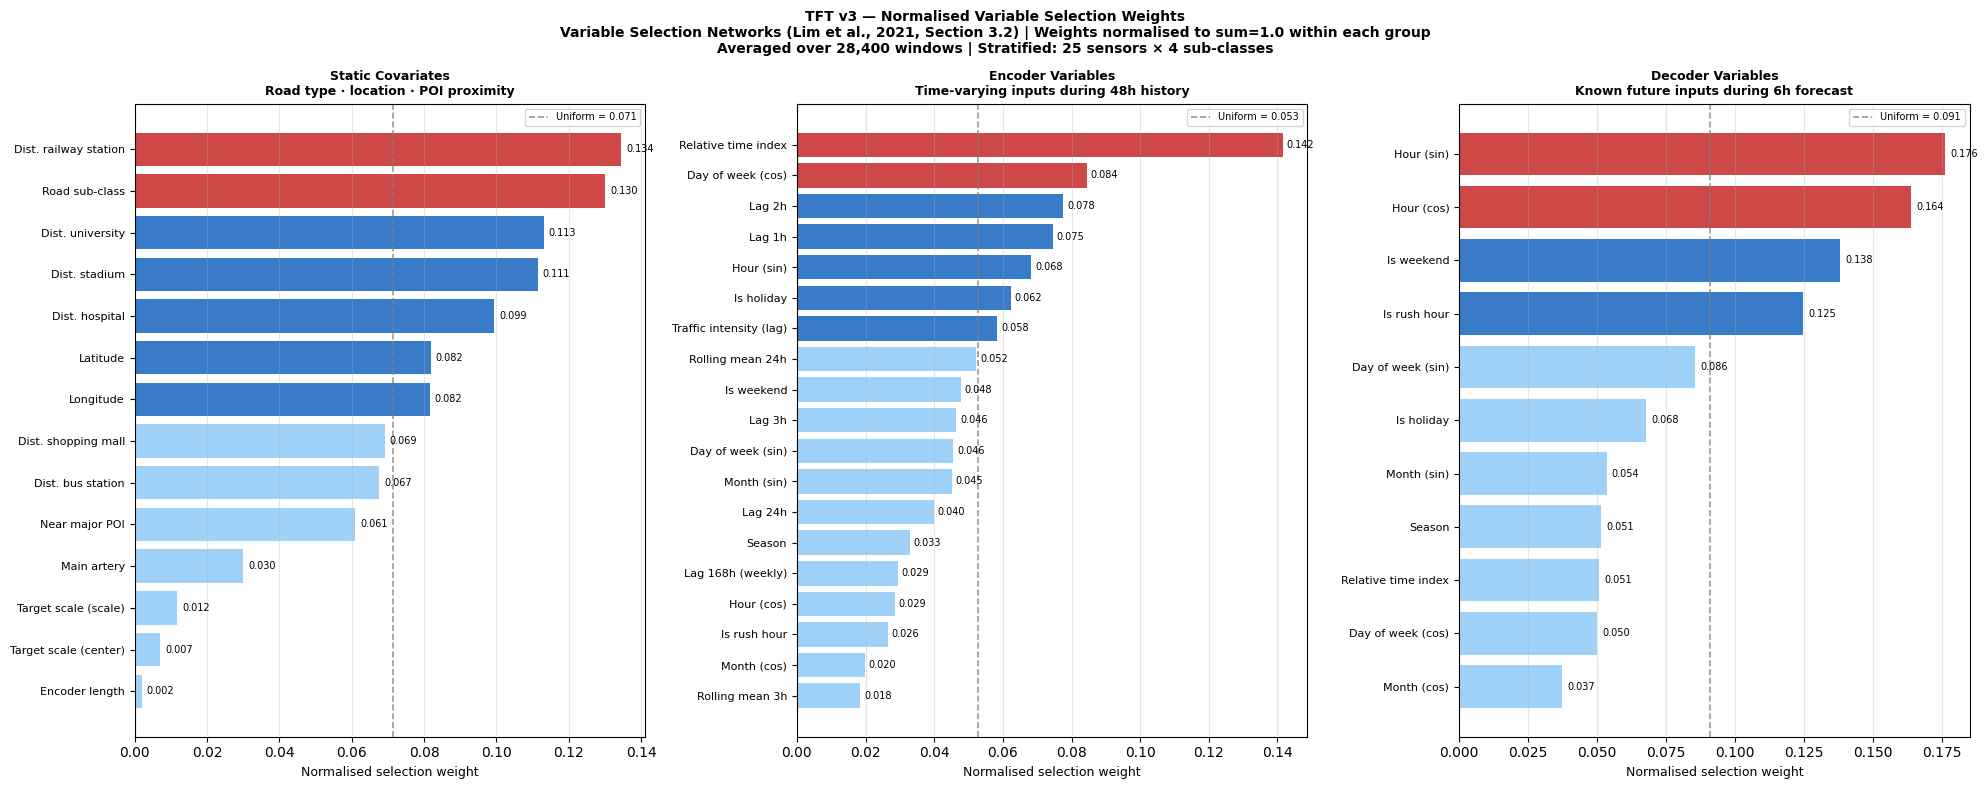

Saved: /home/iai-labor/traffic_project/explainability_figures/tft_v3_variable_selection_normalised.png

Static variables (ranked):
  Feature                          Weight   vs uniform
  Dist. railway station            0.1344       1.88x
  Road sub-class                   0.1300       1.82x
  Dist. university                 0.1131       1.58x
  Dist. stadium                    0.1114       1.56x
  Dist. hospital                   0.0994       1.39x
  Latitude                         0.0818       1.15x
  Longitude                        0.0816       1.14x
  Dist. shopping mall              0.0691       0.97x
  Dist. bus station                0.0675       0.94x
  Near major POI                   0.0610       0.85x
  Main artery                      0.0300       0.42x
  Target scale (scale)             0.0117       0.16x
  Target scale (center)            0.0071       0.10x
  Encoder length                   0.0019       0.03x

Encoder variables (ranked):
  Feature                    

In [5]:
# ── Normalised variable selection weights — 3-panel figure ────────────────────

def plot_importance(ax, names, values, title, subtitle):
    order   = np.argsort(values)
    labels  = get_labels([names[i] for i in order])
    vals    = values[order]
    uniform = 1.0 / len(values)
    colors  = [
        "#C62828" if v >= np.percentile(vals, 90) else
        "#1565C0" if v >= uniform else
        "#90CAF9"
        for v in vals
    ]
    bars = ax.barh(range(len(labels)), vals,
                   color=colors, alpha=0.85)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Normalised selection weight", fontsize=9)
    ax.set_title(f"{title}\n{subtitle}", fontsize=9,
                 fontweight="bold")
    ax.axvline(x=uniform, color="gray", linestyle="--",
               linewidth=1.2, alpha=0.8,
               label=f"Uniform = {uniform:.3f}")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3, axis="x")
    for bar, val in zip(bars, vals):
        ax.text(val + uniform * 0.02,
                bar.get_y() + bar.get_height()/2,
                f"{val:.3f}", va="center", fontsize=7)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))
fig.suptitle(
    "TFT v3 — Normalised Variable Selection Weights\n" | "
    "Weights normalised to sum=1.0 within each group\n"
    f"Averaged over {len(interp_dataset):,} windows | "
    "Stratified: 25 sensors × 4 sub-classes",
    fontsize=10, fontweight="bold"
)

plot_importance(axes[0], static_names,  static_norm,
    "Static Covariates",
    "Road type · location · POI proximity")
plot_importance(axes[1], encoder_names, encoder_norm,
    "Encoder Variables",
    "Time-varying inputs during 48h history")
plot_importance(axes[2], decoder_names, decoder_norm,
    "Decoder Variables",
    "Known future inputs during 6h forecast")

plt.tight_layout()
fig_path = os.path.join(
    FIGURES_DIR, "tft_v3_variable_selection_normalised.png"
)
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Print ranked tables ────────────────────────────────────────────────────────
for group_name, names, values in [
    ("Static",  static_names,  static_norm),
    ("Encoder", encoder_names, encoder_norm),
    ("Decoder", decoder_names, decoder_norm),
]:
    print(f"\n{group_name} variables (ranked):")
    print(f"  {'Feature':<30} {'Weight':>8} {'vs uniform':>12}")
    uniform = 1.0 / len(values)
    for i in np.argsort(values)[::-1]:
        label = get_labels([names[i]])[0]
        print(f"  {label:<30} {values[i]:>8.4f} "
              f"{values[i]/uniform:>10.2f}x")

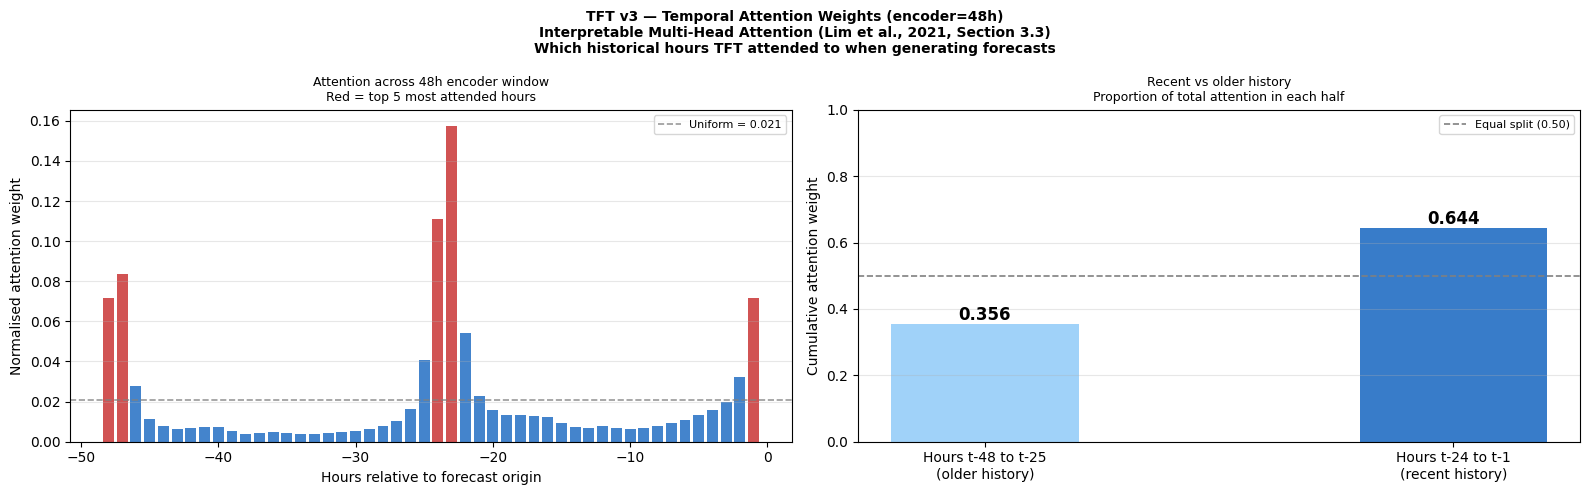

Saved: /home/iai-labor/traffic_project/explainability_figures/tft_v3_attention_weights.png

Recent 24h: 64.4% | Older 24h: 35.6%


In [6]:
# ── Attention weights — overall and per sub-class ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(
    "TFT v3 — Temporal Attention Weights (encoder=48h)\n"
    "Interpretable Multi-Head Attention\n"
    "Which historical hours TFT attended to when generating forecasts",
    fontsize=10, fontweight="bold"
)

# Panel 1 — Attention bar chart
ax1 = axes[0]
bar_colors = ["#C62828" if i in top_5 else "#1565C0"
              for i in range(len(attn_norm))]
ax1.bar(x_hours, attn_norm,
        color=bar_colors, alpha=0.80, width=0.8)
ax1.axhline(
    y=1/CFG["max_encoder_length"],
    color="gray", linestyle="--", linewidth=1.2,
    alpha=0.8,
    label=f"Uniform = {1/CFG['max_encoder_length']:.3f}"
)
ax1.set_xlabel("Hours relative to forecast origin", fontsize=10)
ax1.set_ylabel("Normalised attention weight", fontsize=10)
ax1.set_title(
    "Attention across 48h encoder window\n"
    "Red = top 5 most attended hours",
    fontsize=9
)
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3, axis="y")

# Panel 2 — Recent vs older split
ax2 = axes[1]
categories  = [
    "Hours t-48 to t-25\n(older history)",
    "Hours t-24 to t-1\n(recent history)"
]
values_attn = [older_attn, recent_attn]
colors_attn = ["#90CAF9", "#1565C0"]
bars = ax2.bar(categories, values_attn,
               color=colors_attn, alpha=0.85, width=0.4)
ax2.axhline(y=0.5, color="gray", linestyle="--",
            linewidth=1.2, label="Equal split (0.50)")
for bar, val in zip(bars, values_attn):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.01,
             f"{val:.3f}", ha="center",
             fontsize=12, fontweight="bold")
ax2.set_ylabel("Cumulative attention weight", fontsize=10)
ax2.set_title(
    "Recent vs older history\n"
    "Proportion of total attention in each half",
    fontsize=9
)
ax2.set_ylim(0, 1.0)
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "tft_v3_attention_weights.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")
print(f"\nRecent 24h: {recent_attn:.1%} | Older 24h: {older_attn:.1%}")

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Running per sub-class interpret_output()...
  URB_normal: 7,100 windows


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


    ✓ Done
  URB_ramp: 7,100 windows


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


    ✓ Done
  M30: 7,100 windows


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


    ✓ Done
  C30: 7,100 windows
    ✓ Done

All sub-classes complete


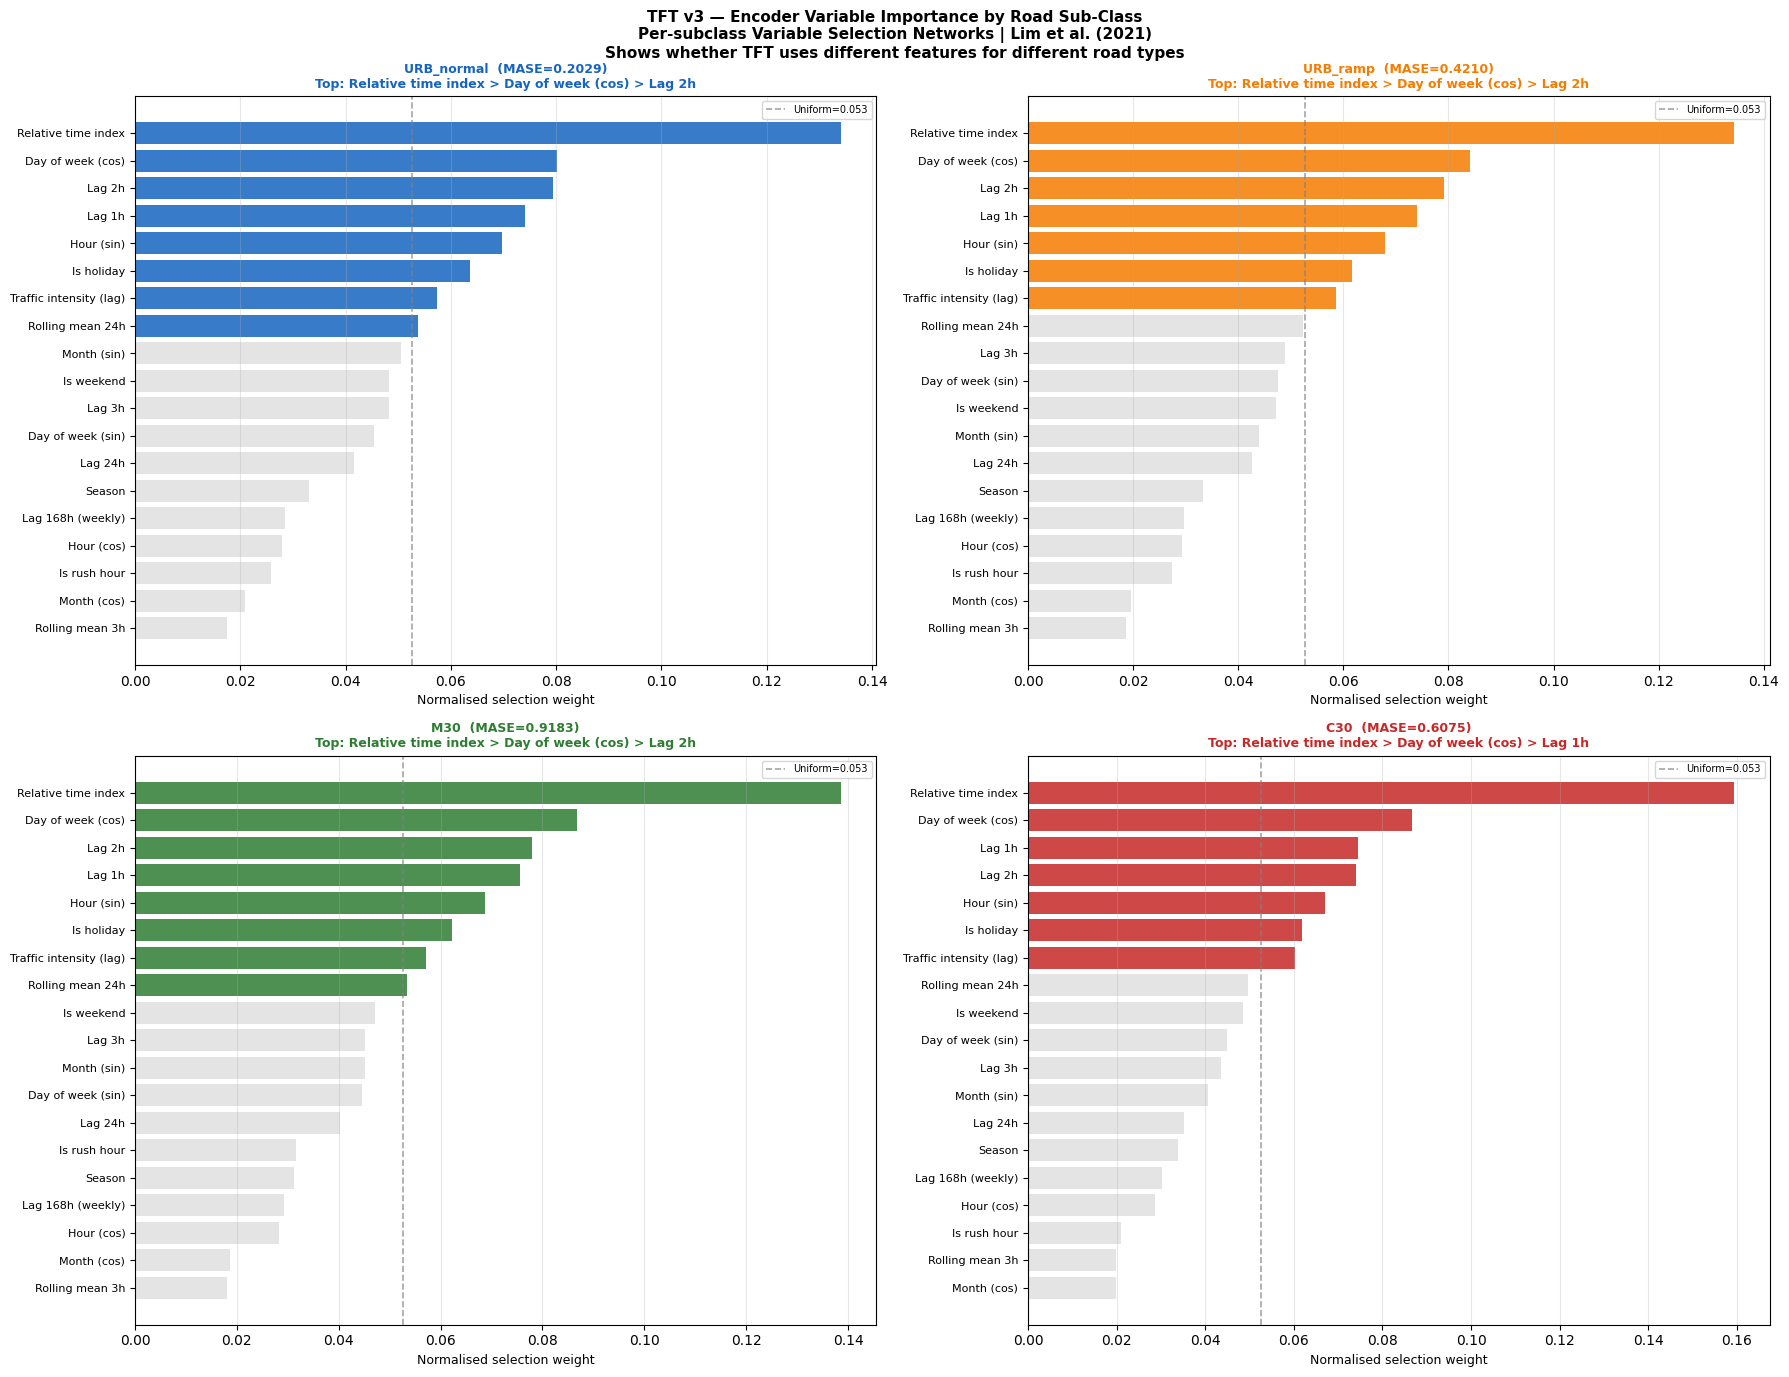

Saved: /home/iai-labor/traffic_project/explainability_figures/tft_v3_subclass_encoder_importance.png


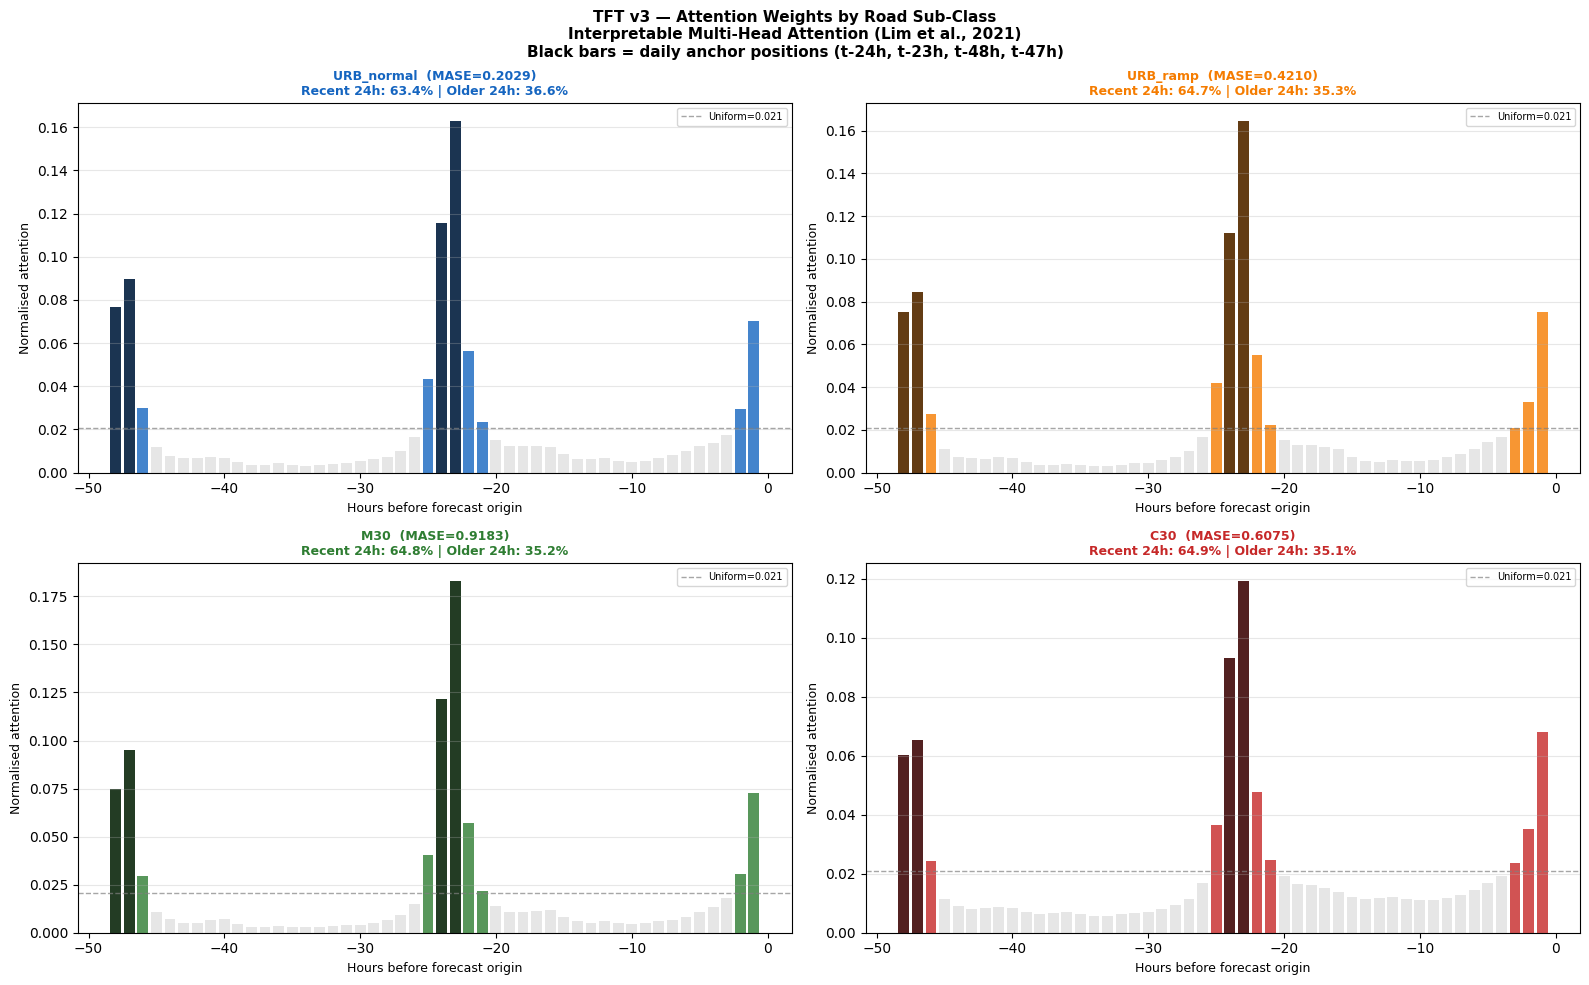

Saved: /home/iai-labor/traffic_project/explainability_figures/tft_v3_attention_by_subclass.png

Attention split by sub-class:
Sub-class        Recent 24h    Older 24h    Peak at
----------------------------------------------------
URB_normal           63.4%       36.6%   t-23h
URB_ramp             64.7%       35.3%   t-23h
M30                  64.8%       35.2%   t-23h
C30                  64.9%       35.1%   t-23h


In [7]:
# ── Per sub-class interpret_output() ──────────────────────────────────────────
# uses different features for different road types

print("Running per sub-class interpret_output()...")
subclass_interpretations = {}

for enc, name in SUBCLASS_NAMES.items():
    class_sensors_sample = [
        s for s in interp_sensors
        if sensor_to_class.get(s, -1) == enc
    ]
    df_class = df_test[
        df_test["sensor_str"].isin(class_sensors_sample) &
        (df_test["time_idx"] >= mid_test - window) &
        (df_test["time_idx"] <= mid_test + window)
    ].copy()

    if len(df_class) == 0:
        print(f"  {name}: no data — skipping")
        continue

    class_dataset = TimeSeriesDataSet.from_dataset(
        training_dataset, df_class,
        min_prediction_idx = val_end_idx + 1,
        predict            = False,
        stop_randomization = True,
    )
    class_loader = class_dataset.to_dataloader(
        train=False, batch_size=32, num_workers=0, shuffle=False
    )
    print(f"  {name}: {len(class_dataset):,} windows")

    torch.cuda.empty_cache()
    class_output = best_tft.predict(
        class_loader, mode="raw", return_x=True,
        trainer_kwargs=dict(
            accelerator="gpu", devices=1,
            enable_progress_bar=False
        ),
    )
    class_interp = best_tft.interpret_output(
        class_output[0], reduction="mean"
    )

    enc_arr  = class_interp["encoder_variables"].cpu().numpy()
    attn_arr = class_interp["attention"].cpu().numpy()
    subclass_interpretations[name] = {
        "encoder":   enc_arr  / enc_arr.sum(),
        "attention": attn_arr / attn_arr.sum(),
    }
    print(f"    ✓ Done")

print("\nAll sub-classes complete")

# ── Figure: per sub-class encoder importance ───────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle(
    "TFT v3 — Encoder Variable Importance by Road Sub-Class\n"
    "Per-subclass Variable Selection Networks | Lim et al. (2021)\n"
    "Shows whether TFT uses different features for different road types",
    fontsize=11, fontweight="bold"
)

MASE_VALS = {
    "URB_normal": 0.2029,
    "URB_ramp":   0.4210,
    "M30":        0.9183,
    "C30":        0.6075,
}

for ax, (name, color) in zip(
    axes.flat,
    [("URB_normal","#1565C0"), ("URB_ramp","#F57C00"),
     ("M30","#2E7D32"), ("C30","#C62828")]
):
    if name not in subclass_interpretations:
        ax.set_title(f"{name} — no data")
        continue

    enc_vals  = subclass_interpretations[name]["encoder"]
    enc_order = np.argsort(enc_vals)
    labels_e  = get_labels([encoder_names[i] for i in enc_order])
    vals_e    = enc_vals[enc_order]
    uniform_e = 1.0 / len(enc_vals)

    bar_colors = [color if v >= uniform_e else "#E0E0E0"
                  for v in vals_e]
    ax.barh(range(len(labels_e)), vals_e,
            color=bar_colors, alpha=0.85)
    ax.set_yticks(range(len(labels_e)))
    ax.set_yticklabels(labels_e, fontsize=8)
    ax.set_xlabel("Normalised selection weight", fontsize=9)
    ax.axvline(x=uniform_e, color="gray", linestyle="--",
               linewidth=1.2, alpha=0.7,
               label=f"Uniform={uniform_e:.3f}")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3, axis="x")

    top3 = [
        get_labels([encoder_names[i]])[0]
        for i in reversed(np.argsort(enc_vals)[-3:])
    ]
    ax.set_title(
        f"{name}  (MASE={MASE_VALS[name]:.4f})\n"
        f"Top: {' > '.join(top3)}",
        fontsize=9, fontweight="bold", color=color
    )

plt.tight_layout()
fig_path = os.path.join(
    FIGURES_DIR, "tft_v3_subclass_encoder_importance.png"
)
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Attention by sub-class ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    "TFT v3 — Attention Weights by Road Sub-Class\n"
    "Interpretable Multi-Head Attention (Lim et al., 2021)\n"
    "Black bars = daily anchor positions (t-24h, t-23h, t-48h, t-47h)",
    fontsize=11, fontweight="bold"
)

for ax, (name, color) in zip(
    axes.flat,
    [("URB_normal","#1565C0"), ("URB_ramp","#F57C00"),
     ("M30","#2E7D32"), ("C30","#C62828")]
):
    if name not in subclass_interpretations:
        ax.set_title(f"{name} — no data")
        continue

    attn_sc   = subclass_interpretations[name]["attention"]
    recent_sc = float(attn_sc[-24:].sum())
    older_sc  = float(attn_sc[:24].sum())
    uniform   = 1.0 / len(attn_sc)

    bar_c = [color if v >= uniform else "#E0E0E0"
             for v in attn_sc]
    ax.bar(x_hours, attn_sc, color=bar_c, alpha=0.80, width=0.8)

    for anchor in [-24, -23, -48, -47]:
        idx = anchor + CFG["max_encoder_length"]
        if 0 <= idx < len(attn_sc):
            ax.bar(x_hours[idx], attn_sc[idx],
                   color="black", alpha=0.6, width=0.8)

    ax.axhline(y=uniform, color="gray", linestyle="--",
               linewidth=1.0, alpha=0.7,
               label=f"Uniform={uniform:.3f}")
    ax.set_xlabel("Hours before forecast origin", fontsize=9)
    ax.set_ylabel("Normalised attention", fontsize=9)
    ax.set_title(
        f"{name}  (MASE={MASE_VALS[name]:.4f})\n"
        f"Recent 24h: {recent_sc:.1%} | Older 24h: {older_sc:.1%}",
        fontsize=9, fontweight="bold", color=color
    )
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
fig_path = os.path.join(
    FIGURES_DIR, "tft_v3_attention_by_subclass.png"
)
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Attention summary table ────────────────────────────────────────────────────
print("\nAttention split by sub-class:")
print(f"{'Sub-class':<14} {'Recent 24h':>12} {'Older 24h':>12} "
      f"{'Peak at':>10}")
print("-" * 52)
for name in ["URB_normal","URB_ramp","M30","C30"]:
    if name not in subclass_interpretations:
        continue
    attn_sc   = subclass_interpretations[name]["attention"]
    peak_idx  = np.argmax(attn_sc)
    recent_sc = float(attn_sc[-24:].sum())
    older_sc  = float(attn_sc[:24].sum())
    print(f"{name:<14} {recent_sc:>11.1%} {older_sc:>11.1%} "
          f"  t{x_hours[peak_idx]:+d}h")

In [8]:
# ── Save all interpretation results ───────────────────────────────────────────
interpretation_results = {
    "model":       "TFT v3",
    "method":      "interpret_output() — Lim et al. (2021)",
    "n_windows":   len(interp_dataset),
    "n_sensors":   len(interp_sensors),
    "n_per_class": N_INTERP,
    "overall": {
        "static": {
            static_names[i]: float(static_norm[i])
            for i in range(len(static_names))
        },
        "encoder": {
            encoder_names[i]: float(encoder_norm[i])
            for i in range(len(encoder_names))
        },
        "decoder": {
            decoder_names[i]: float(decoder_norm[i])
            for i in range(len(decoder_names))
        },
        "attention":           attn_norm.tolist(),
        "attention_recent_24h": float(recent_attn),
        "attention_older_24h":  float(older_attn),
        "top5_attention_hours": {
            f"t{x_hours[i]:+d}h": float(attn_norm[i])
            for i in top_5
        },
    },
    "per_subclass": {
        name: {
            "encoder": {
                encoder_names[i]: float(
                    subclass_interpretations[name]["encoder"][i]
                )
                for i in range(len(encoder_names))
            },
            "attention_recent_24h": float(
                subclass_interpretations[name]["attention"][-24:].sum()
            ),
        }
        for name in subclass_interpretations
    },
}

save_path = os.path.join(
    FIGURES_DIR, "tft_v3_interpretation_results.json"
)
with open(save_path, "w") as f:
    json.dump(interpretation_results, f, indent=2)
print(f"Results saved: {save_path}")

# ── Final figure checklist ─────────────────────────────────────────────────────
print("\nAll figures:")
for fname in [
    "tft_v3_variable_selection_normalised.png",
    "tft_v3_attention_weights.png",
    "tft_v3_subclass_encoder_importance.png",
    "tft_v3_attention_by_subclass.png",
]:
    fpath = os.path.join(FIGURES_DIR, fname)
    exists = "✓" if os.path.exists(fpath) else "✗ MISSING"
    print(f"  {exists}  {fname}")

print("\n✓ tft_interpretability.ipynb complete")

Results saved: /home/iai-labor/traffic_project/explainability_figures/tft_v3_interpretation_results.json

All figures:
  ✓  tft_v3_variable_selection_normalised.png
  ✓  tft_v3_attention_weights.png
  ✓  tft_v3_subclass_encoder_importance.png
  ✓  tft_v3_attention_by_subclass.png

✓ tft_interpretability.ipynb complete
